# 02 – Exploratory Data Analysis

**Goal:** Get a first look at the draws: how often each number appears and how this compares with what a fair 6/37 lottery would produce.

**Input:** `data/processed/lotto_current_format.csv`

## 1. Load the cleaned data

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/lotto_current_format.csv", parse_dates=["date"])
num_cols = ["n1", "n2", "n3", "n4", "n5", "n6"]

print(df.shape)

(1744, 11)


## 2. Frequency of the main numbers
In a fair 6/37 lottery, each number appears in a draw with probability 6/37, so with N draws I expect each number to be drawn about N × 6/37 times. Real counts will never match this exactly because of random variation. The question is whether the differences are larger than chance would explain, and this is what the statistical tests later will answer.

In [3]:
# stack() puts the six columns into one long series of all drawn numbers
main_counts = df[num_cols].stack().value_counts().sort_index()

expected = len(df) * 6 / 37
print(f"Expected count per number: {expected:.1f}")

main_counts.describe()

Expected count per number: 282.8


count     37.000000
mean     282.810811
std       15.021906
min      245.000000
25%      277.000000
50%      281.000000
75%      291.000000
max      315.000000
Name: count, dtype: float64

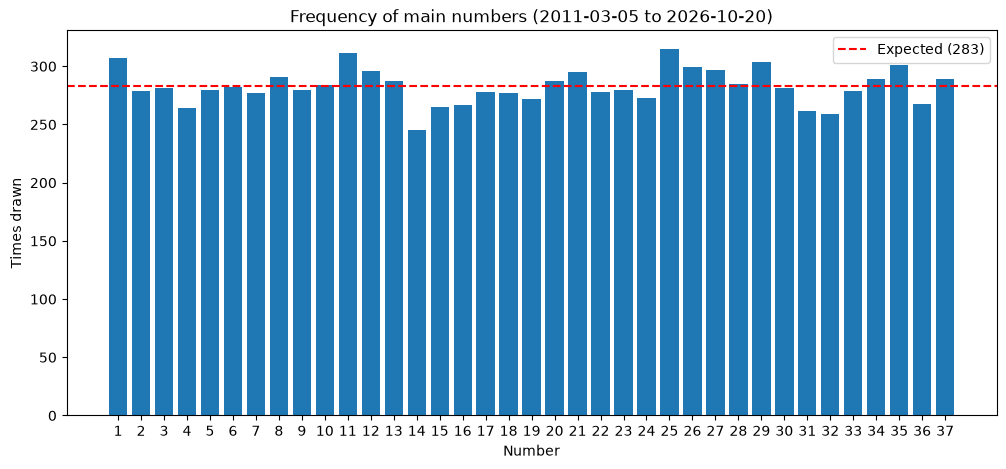

In [4]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(main_counts.index, main_counts.values)
ax.axhline(expected, color="red", linestyle="--", label=f"Expected ({expected:.0f})")

ax.set_xlabel("Number")
ax.set_ylabel("Times drawn")
ax.set_title("Frequency of main numbers (2011-03-05 to 2026-10-20)")
ax.set_xticks(range(1, 38))
ax.legend()

plt.show()

**Observations**
- With 1,744 draws, a fair 6/37 lottery would produce each number about 283 times.
- Observed counts range from 245 (number 14) to 315 (number 25), with a standard deviation of 15.0.
- As a rough reference, if every draw were independent, the expected standard deviation of such counts would be √(N·p·(1−p)) ≈ 15.4. The spread seen here is about what chance alone produces.
- No number stands far apart from the others. Whether the differences are statistically meaningful is tested in the hypothesis testing notebook.

## 3. Frequency of the strong number
The strong number is drawn separately from 1 to 7, so in a fair lottery each value has probability 1/7 per draw and should appear about N/7 times.

In [5]:
strong_counts = df["strong"].value_counts().sort_index()

expected_strong = len(df) / 7
print(f"Expected count per strong number: {expected_strong:.1f}")

strong_counts

Expected count per strong number: 249.1


strong
1    241
2    248
3    255
4    236
5    261
6    264
7    239
Name: count, dtype: int64

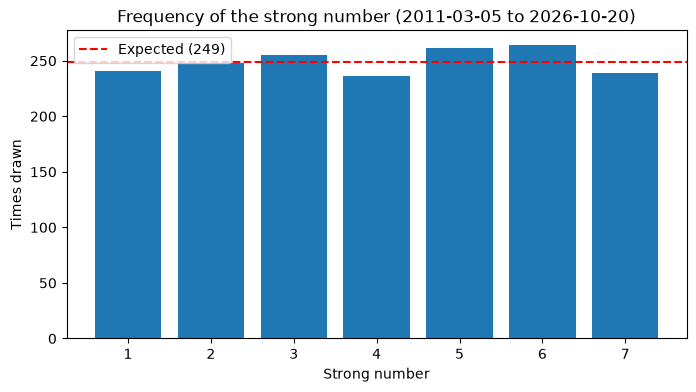

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(strong_counts.index, strong_counts.values)
ax.axhline(expected_strong, color="red", linestyle="--", label=f"Expected ({expected_strong:.0f})")

ax.set_xlabel("Strong number")
ax.set_ylabel("Times drawn")
ax.set_title("Frequency of the strong number (2011-03-05 to 2026-10-20)")
ax.set_xticks(range(1, 8))
ax.legend()

plt.show()

**Observations**
- With 1,744 draws, each strong number is expected about 249 times. Observed counts range from 236 (number 4) to 264 (number 6).
- The largest deviation from the expected count is about 15, which is roughly one standard deviation of the random variation expected under a fair draw (about 14.6).
- Nothing in the chart suggests a strong number that is clearly favored or avoided. A formal test follows in the hypothesis testing notebook.

In [ ]:
## 4. Sum of the six main numbers
The sum of the six main numbers summarizes a draw in a single value. In a fair draw it should follow a bell-shaped distribution centered around 114 (the mean of the numbers 1–37 is 19, multiplied by 6).

count    1744.000000
mean      114.105505
std        24.456767
min        39.000000
25%        97.000000
50%       114.000000
75%       131.000000
max       187.000000
Name: sum_main, dtype: float64


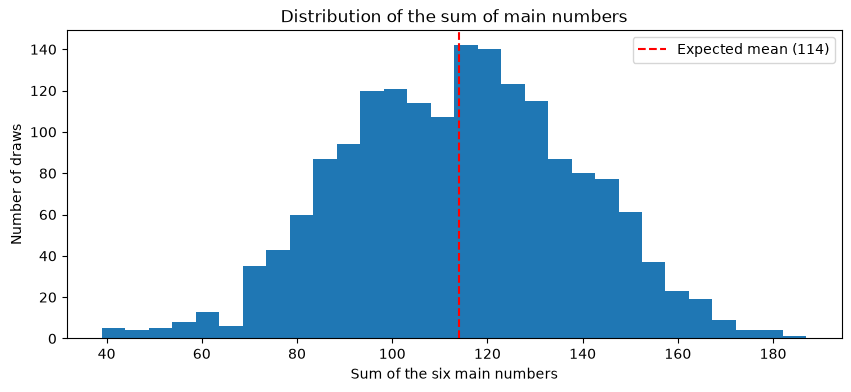

In [7]:
df["sum_main"] = df[num_cols].sum(axis=1)
print(df["sum_main"].describe())

fig, ax = plt.subplots(figsize=(10, 4))

ax.hist(df["sum_main"], bins=30)
ax.axvline(114, color="red", linestyle="--", label="Expected mean (114)")

ax.set_xlabel("Sum of the six main numbers")
ax.set_ylabel("Number of draws")
ax.set_title("Distribution of the sum of main numbers")
ax.legend()

plt.show()

**Observations**
- The sum of the six main numbers is bell-shaped and centered close to the theoretical value: the observed mean is 114.1 (expected 114).
- The observed standard deviation is 24.5, very close to the theoretical value of about 24.3 for six numbers drawn without replacement from 1–37.
- The sums range from 39 to 187. The histogram looks slightly bumpy, which is normal for 1,744 draws split into 30 bins.